How quickly does the giant connected component collapse under random failure versus targeted attack?

In [1]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
PROJECT_DIR = "/content/drive/MyDrive/NetworkScience/NSProject"

DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures", "B")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results", "B")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Project paths configured!")

Project paths configured!


In [4]:
# Load real network
DATA_PATH = os.path.join(DATA_DIR, "CA-GrQc.txt")

G_full = nx.read_edgelist(
    DATA_PATH,
    nodetype=int
)

# Extract largest connected component
largest_component = max(
    nx.connected_components(G_full),
    key=len
)

G_real = G_full.subgraph(largest_component).copy()

# Generate configuration model
degree_sequence = [d for _, d in G_real.degree()]

G_config = nx.configuration_model(
    degree_sequence,
    seed=42
)

# Generate BA model
G_ba = nx.barabasi_albert_graph(
    n=G_real.number_of_nodes(),
    m=3,
    seed=42
)

print("REAL:", G_real.number_of_nodes(), G_real.number_of_edges())
print("CONFIGURATION:", G_config.number_of_nodes(), G_config.number_of_edges())
print("BA:", G_ba.number_of_nodes(), G_ba.number_of_edges())

REAL: 4158 13428
CONFIGURATION: 4158 13428
BA: 4158 12465


In [5]:
for name, G in {
    "Real": G_real,
    "Configuration": G_config,
    "BA": G_ba
}.items():

    print(f"\n{name}")
    print("Nodes:", G.number_of_nodes())
    print("Edges:", G.number_of_edges())
    print("Connected:", nx.is_connected(G))


Real
Nodes: 4158
Edges: 13428
Connected: True

Configuration
Nodes: 4158
Edges: 13428
Connected: False

BA
Nodes: 4158
Edges: 12465
Connected: True


# Define the robustness measurement

## the relative size of the largest connected component

In [6]:
def giant_component_ratio(G, initial_nodes):
    if G.number_of_nodes() == 0:
        return 0

    largest = max(
        (len(c) for c in nx.connected_components(G)),
        default=0
    )

    return largest / initial_nodes

print("Measurement function ready!")

Measurement function ready!


In [8]:
G_config_simple = nx.Graph(G_config)
G_config_simple.remove_edges_from(nx.selfloop_edges(G_config_simple))

networks = {
    "Real": G_real,
    "Configuration": G_config_simple,
    "BA": G_ba
}

for name, G in networks.items():
    print(name, G.number_of_nodes(), G.number_of_edges())

Real 4158 13428
Configuration 4158 13360
BA 4158 12465


## Define the robustness measurement

This function removes nodes in a specified order and measures the relative size of the largest connected component at each removal step.

In [9]:
def robustness_curve(G, removal_order, fractions):
    G_temp = G.copy()
    initial_nodes = G.number_of_nodes()
    results = []

    for fraction in fractions:
        target_removed = int(fraction * initial_nodes)

        while initial_nodes - G_temp.number_of_nodes() < target_removed:
            if G_temp.number_of_nodes() == 0:
                break
            G_temp.remove_node(removal_order[initial_nodes - G_temp.number_of_nodes()])

        results.append(giant_component_ratio(G_temp, initial_nodes))

    return results

fractions = np.arange(0, 0.51, 0.05)
print("Robustness function ready!")

Robustness function ready!


## Test random node removal on the real network.

In [10]:
rng = np.random.default_rng(42)

random_order = rng.permutation(list(G_real.nodes()))

random_curve = robustness_curve(
    G_real, random_order, fractions
)

print("Fractions removed:", fractions)
print("Giant component ratios:", random_curve)

Fractions removed: [0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5 ]
Giant component ratios: [1.0, 0.9268879268879269, 0.8525733525733525, 0.7797017797017797, 0.7126022126022126, 0.6426166426166426, 0.570947570947571, 0.506974506974507, 0.4357864357864358, 0.37999037999038, 0.32395382395382394]


## Test targeted removal by highest initial degree.

In [11]:
degree_order = [
    node for node, degree in
    sorted(G_real.degree(), key=lambda x: x[1], reverse=True)
]

degree_curve = robustness_curve(
    G_real, degree_order, fractions
)

print("Fractions removed:", fractions)
print("Giant component ratios:", degree_curve)

Fractions removed: [0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5 ]
Giant component ratios: [1.0, 0.8792688792688793, 0.7159692159692159, 0.4199134199134199, 0.03342953342953343, 0.00937950937950938, 0.00481000481000481, 0.0036075036075036075, 0.0026455026455026454, 0.001924001924001924, 0.001443001443001443]


## Targeted removal by highest current degree (adaptive attack)

Unlike Cell 10, this recalculates node degrees after every removal.

In [12]:
def adaptive_degree_curve(G, fractions):
    G_temp = G.copy()
    initial_nodes = G.number_of_nodes()
    results = []

    for fraction in fractions:
        target_removed = int(fraction * initial_nodes)

        while initial_nodes - G_temp.number_of_nodes() < target_removed:
            if G_temp.number_of_nodes() == 0:
                break

            node = max(G_temp.degree(), key=lambda x: x[1])[0]
            G_temp.remove_node(node)

        results.append(giant_component_ratio(G_temp, initial_nodes))

    return results

adaptive_curve = adaptive_degree_curve(G_real, fractions)

print("Fractions removed:", fractions)
print("Giant component ratios:", adaptive_curve)

Fractions removed: [0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5 ]
Giant component ratios: [1.0, 0.8292448292448292, 0.6245791245791246, 0.19408369408369408, 0.010582010582010581, 0.002886002886002886, 0.0016835016835016834, 0.000962000962000962, 0.000481000481000481, 0.000481000481000481, 0.000481000481000481]


## Highest betweenness attack (static ranking)

In [13]:
betweenness = nx.betweenness_centrality(G_real)

betweenness_order = sorted(
    betweenness,
    key=betweenness.get,
    reverse=True
)

betweenness_curve = robustness_curve(
    G_real, betweenness_order, fractions
)

print("Fractions removed:", fractions)
print("Giant component ratios:", betweenness_curve)

Fractions removed: [0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5 ]
Giant component ratios: [1.0, 0.7445887445887446, 0.4066859066859067, 0.035594035594035595, 0.01875901875901876, 0.00962000962000962, 0.008177008177008177, 0.008177008177008177, 0.008177008177008177, 0.007696007696007696, 0.007696007696007696]


## Compare all four strategies on the real network

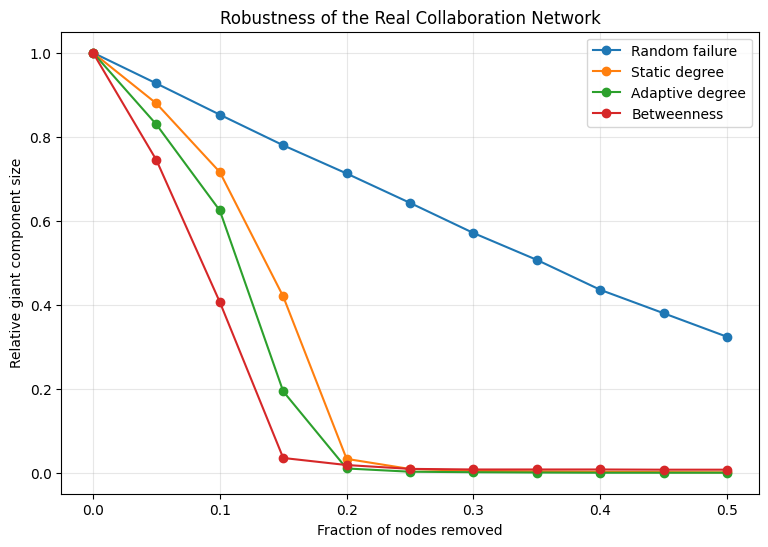

In [14]:
plt.figure(figsize=(9, 6))

plt.plot(fractions, random_curve, marker='o', label='Random failure')
plt.plot(fractions, degree_curve, marker='o', label='Static degree')
plt.plot(fractions, adaptive_curve, marker='o', label='Adaptive degree')
plt.plot(fractions, betweenness_curve, marker='o', label='Betweenness')

plt.xlabel('Fraction of nodes removed')
plt.ylabel('Relative giant component size')
plt.title('Robustness of the Real Collaboration Network')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(FIGURES_DIR, 'B3_real_robustness.png'), dpi=300)
plt.show()

The graph shows that the real collaboration network is robust against random failures but highly vulnerable to targeted attacks.
- Random failure (blue): The largest connected component decreases gradually. Even after removing 50% of nodes, about 32.4% of the original network remains connected.
- Static degree attack (orange): Removing high-degree nodes causes a sharp decline. At 15% removal, only 42.0% remains; at 20%, about 3.3%.
- Adaptive degree attack (green): Recalculating degrees after each removal makes the attack more damaging. At 15% removal, only 19.4% remains.
- Betweenness attack (red): This is the most damaging strategy at the early stages. At 10% removal, only 40.7% remains; at 15%, just 3.6%.
Conclusion: The network depends heavily on important central nodes. Random failures do not immediately fragment it, but deliberately removing highly connected or structurally central nodes causes rapid fragmentation. This is typical of networks with a heterogeneous structure and important hubs or bridges.

## Which network is most resistant to:

### random node failures

In [15]:
random_results = {}

for name, G in networks.items():
    simulations = []

    for seed in range(30):
        rng = np.random.default_rng(seed)
        order = rng.permutation(list(G.nodes()))
        curve = robustness_curve(G, order, fractions)
        simulations.append(curve)

    random_results[name] = np.array(simulations)

    print(name, "completed")

Real completed
Configuration completed
BA completed


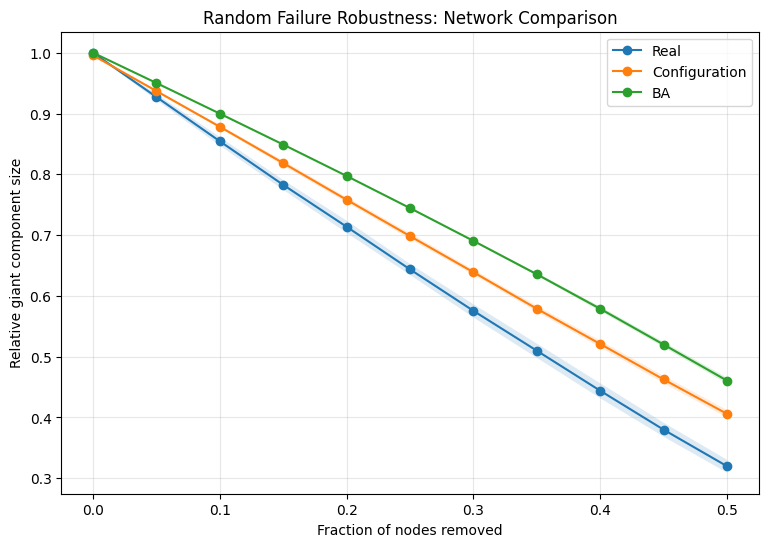

In [16]:
plt.figure(figsize=(9, 6))

for name, results in random_results.items():
    mean_curve = results.mean(axis=0)
    std_curve = results.std(axis=0)

    plt.plot(fractions, mean_curve, marker='o', label=name)
    plt.fill_between(
        fractions,
        mean_curve - std_curve,
        mean_curve + std_curve,
        alpha=0.15
    )

plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative giant component size")
plt.title("Random Failure Robustness: Network Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(FIGURES_DIR, "B3_random_comparison.png"), dpi=300)
plt.show()

### Static degree attack

In [17]:
targeted_results = {}

for name, G in networks.items():
    order = [
        node for node, degree in
        sorted(G.degree(), key=lambda x: x[1], reverse=True)
    ]

    targeted_results[name] = robustness_curve(
        G, order, fractions
    )

    print(name, "completed")

Real completed
Configuration completed
BA completed


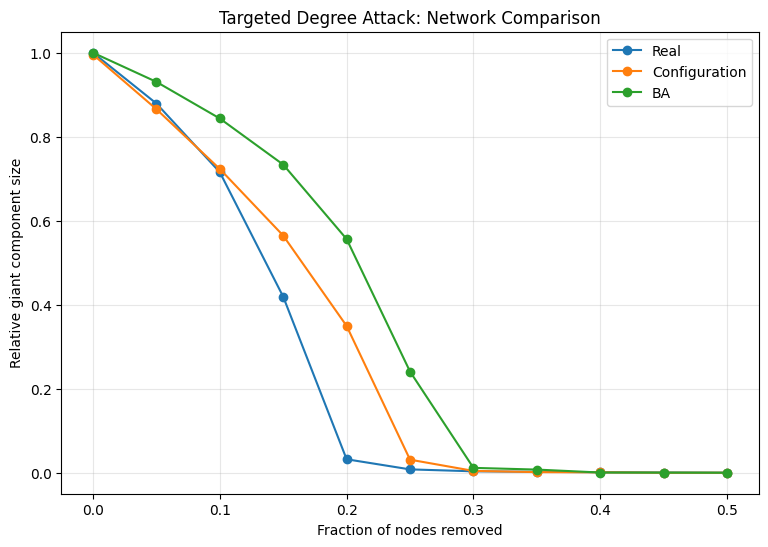

In [18]:
plt.figure(figsize=(9, 6))

for name, curve in targeted_results.items():
    plt.plot(fractions, curve, marker='o', label=name)

plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative giant component size")
plt.title("Targeted Degree Attack: Network Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, "B3_targeted_degree_comparison.png"),
    dpi=300
)
plt.show()

### Adaptive degree attack

In [19]:
adaptive_results = {}

for name, G in networks.items():
    adaptive_results[name] = adaptive_degree_curve(G, fractions)
    print(name, "completed")

Real completed
Configuration completed
BA completed


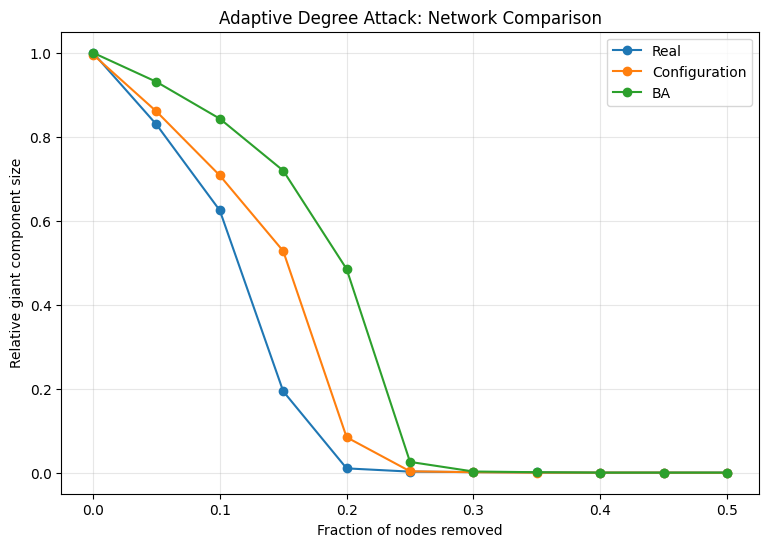

In [20]:
plt.figure(figsize=(9, 6))

for name, curve in adaptive_results.items():
    plt.plot(fractions, curve, marker='o', label=name)

plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative giant component size")
plt.title("Adaptive Degree Attack: Network Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, "B3_adaptive_degree_comparison.png"),
    dpi=300
)
plt.show()

### Betweenness attack

In [21]:
betweenness_results = {}

for name, G in networks.items():
    print("Calculating betweenness for", name)

    centrality = nx.betweenness_centrality(G)

    order = sorted(
        centrality,
        key=centrality.get,
        reverse=True
    )

    betweenness_results[name] = robustness_curve(
        G, order, fractions
    )

    print(name, "completed")

Calculating betweenness for Real
Real completed
Calculating betweenness for Configuration
Configuration completed
Calculating betweenness for BA
BA completed


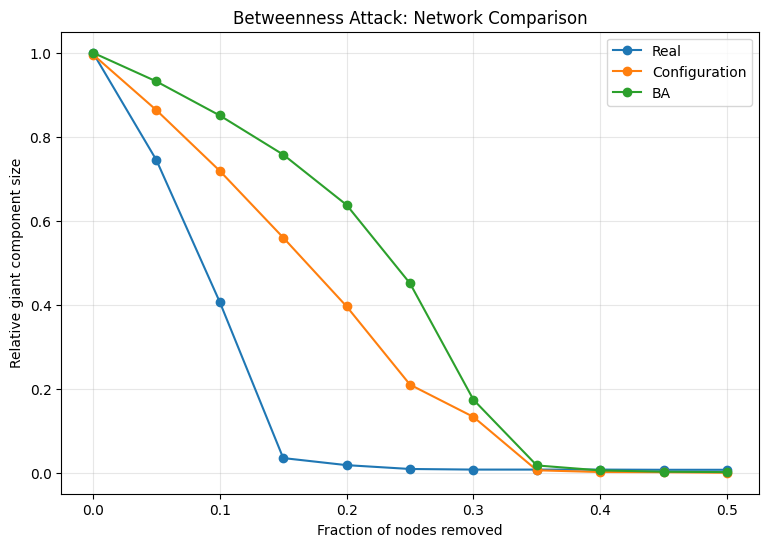

In [22]:
plt.figure(figsize=(9, 6))

for name, curve in betweenness_results.items():
    plt.plot(fractions, curve, marker='o', label=name)

plt.xlabel("Fraction of nodes removed")
plt.ylabel("Relative giant component size")
plt.title("Betweenness Attack: Network Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(FIGURES_DIR, "B3_betweenness_comparison.png"),
    dpi=300
)
plt.show()

## Calculate empirical breakdown thresholds

In [23]:
def find_threshold(curve, fractions):
    for f, size in zip(fractions, curve):
        if size < 0.5:
            return f
    return None

threshold_results = []

for name in networks:
    strategies = {
        "Random": random_results[name].mean(axis=0),
        "Static degree": targeted_results[name],
        "Adaptive degree": adaptive_results[name],
        "Betweenness": betweenness_results[name]
    }

    for strategy, curve in strategies.items():
        threshold_results.append({
            "Network": name,
            "Strategy": strategy,
            "Breakdown threshold": find_threshold(curve, fractions)
        })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Network,Strategy,Breakdown threshold
0,Real,Random,0.40
1,Real,Static degree,0.15
2,Real,Adaptive degree,0.15
3,Real,Betweenness,0.10
4,Configuration,Random,0.45
5,Configuration,Static degree,0.20
6,Configuration,Adaptive degree,0.20
7,Configuration,Betweenness,0.20
8,BA,Random,0.50
9,BA,Static degree,0.25


## Theoretical threshold calculation

we calculate the theoretical random-failure threshold using the Molloy–Reed criterion for each network.

In [24]:
theoretical_results = []

for name, G in networks.items():
    degrees = np.array([d for _, d in G.degree()])

    mean_k = np.mean(degrees)
    mean_k2 = np.mean(degrees ** 2)

    kappa = mean_k2 / mean_k
    p_c = 1 / (kappa - 1)
    f_c = 1 - p_c

    theoretical_results.append({
        "Network": name,
        "Mean degree": mean_k,
        "Kappa": kappa,
        "Theoretical critical fraction remaining": p_c,
        "Theoretical failure threshold": f_c
    })

theoretical_df = pd.DataFrame(theoretical_results)
display(theoretical_df)

,Network,Mean degree,Kappa,Theoretical critical fraction remaining,Theoretical failure threshold
0,Real,6.458874,17.982350,0.058885,0.941115
1,Configuration,6.426166,17.766617,0.059642,0.940358
2,BA,5.995671,17.957561,0.058971,0.941029


In [25]:
threshold_df.to_csv(
    os.path.join(RESULTS_DIR, "B3_empirical_thresholds.csv"),
    index=False
)

print("Empirical thresholds saved.")

Empirical thresholds saved.


## Combine empirical and theoretical thresholds

In [26]:
empirical_wide = threshold_df.pivot(
    index="Network",
    columns="Strategy",
    values="Breakdown threshold"
).reset_index()

final_thresholds = empirical_wide.merge(
    theoretical_df[["Network", "Theoretical failure threshold"]],
    on="Network"
)

display(final_thresholds)

final_thresholds.to_csv(
    os.path.join(RESULTS_DIR, "B3_final_threshold_comparison.csv"),
    index=False
)

print("Final threshold comparison saved.")

,Network,Adaptive degree,Betweenness,Random,Static degree,Theoretical failure threshold
0,BA,0.20,0.25,0.50,0.25,0.941029
1,Configuration,0.20,0.20,0.45,0.20,0.940358
2,Real,0.15,0.10,0.40,0.15,0.941115


Final threshold comparison saved.


In [27]:
curve_data = []

for name in networks:
    for i, f in enumerate(fractions):
        curve_data.append({
            "Network": name,
            "Fraction_removed": f,
            "Random_mean": random_results[name].mean(axis=0)[i],
            "Random_std": random_results[name].std(axis=0)[i],
            "Static_degree": targeted_results[name][i],
            "Adaptive_degree": adaptive_results[name][i],
            "Betweenness": betweenness_results[name][i]
        })

curve_df = pd.DataFrame(curve_data)

curve_df.to_csv(
    os.path.join(RESULTS_DIR, "B3_robustness_curves.csv"),
    index=False
)

print("Robustness curves saved.")

Robustness curves saved.
